# Phase 7 : Modélisation Machine Learning

## Objectif

Construire un modèle capable de prédire les points par match d'un joueur NBA
lors de la saison N+1 à partir des informations disponibles jusqu'à la fin
de la saison N.

L'évaluation doit mesurer la capacité du modèle à généraliser sur des données
qui n'ont pas été utilisées pendant son entraînement ou sa sélection.

## 1. Cadrage du problème ML

**Question prédictive :** peut-on prédire les points par match d'un joueur NBA
en saison N+1 à partir des informations disponibles jusqu'à la fin de la
saison N ?

**Cible :** `pts_next_season`

**Type de problème :** régression.

**Métrique principale :** MAE.

La MAE est privilégiée car elle mesure directement l'erreur moyenne en points
par match. Une MAE de 2 signifie par exemple que les prédictions s'écartent en
moyenne d'environ 2 points par match de la valeur réelle.

**Métriques complémentaires :**
- RMSE, afin de pénaliser davantage les grosses erreurs ;
- R², afin de mesurer la part de variance expliquée.

**Baselines :**
- `DummyRegressor(strategy="mean")` ;
- persistance : prédire pour N+1 le nombre de points observé en saison N.

**Features :** statistiques individuelles, historiques, biographiques,
collectives et informations de roster disponibles en saison N.

Les identifiants, informations non généralisables et toute variable susceptible
de contenir une information future seront exclues avant l'entraînement.

In [60]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


RANDOM_STATE = 42
TARGET = "pts_next_season"


pd.set_option(
    "display.max_columns",
    100
)

pd.set_option(
    "display.max_rows",
    100
)


print("Imports OK")

Imports OK


In [61]:
PROJECT_ROOT = Path.cwd()


if (
    not (PROJECT_ROOT / "data").exists()
    and (PROJECT_ROOT / "ML_NBA_Project" / "data").exists()
):
    PROJECT_ROOT = (
        PROJECT_ROOT
        / "ML_NBA_Project"
    )


PROCESSED_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
)

PHASE4_REPORT_DIR = (
    PROJECT_ROOT
    / "reports"
    / "phase4_transformation"
)

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
)

REPORT_DIR = (
    PROJECT_ROOT
    / "reports"
    / "phase7_modelisation"
)


MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print(
    "Projet :",
    PROJECT_ROOT.resolve()
)

print(
    "Données :",
    PROCESSED_DIR.resolve()
)

print(
    "Rapports :",
    REPORT_DIR.resolve()
)

Projet : C:\Users\USER\OneDrive\LiveCampus\master\cours\machine learning\final\Model
Données : C:\Users\USER\OneDrive\LiveCampus\master\cours\machine learning\final\Model\data\processed
Rapports : C:\Users\USER\OneDrive\LiveCampus\master\cours\machine learning\final\Model\reports\phase7_modelisation


In [62]:
# Chargement du dataset supervisé

df = pd.read_parquet(
    PROCESSED_DIR
    / "nba_player_season_supervised.parquet"
)


print(
    "Dimensions :",
    df.shape
)

print(
    "Période :",
    df["SEASON"].min(),
    "à",
    df["SEASON"].max()
)

print(
    "Cible :",
    TARGET
)

print(
    "Cibles manquantes :",
    df[TARGET].isna().sum()
)

display(
    df[TARGET]
    .describe()
    .to_frame()
)

Dimensions : (9911, 251)
Période : 1996-97 à 2021-22
Cible : pts_next_season
Cibles manquantes : 0


,pts_next_season
count,9911.000000
mean,9.097457
std,6.140855
min,0.000000
25%,4.400000
50%,7.700000
75%,12.600000
max,36.100000


## 2. Audit anti-fuite

Avant de créer `X`, les colonnes sont vérifiées afin d'identifier :

- les informations provenant du futur ;
- les identifiants sans valeur généralisable ;
- les variables techniques ;
- les variables catégorielles à très forte cardinalité.

Aucun preprocessing n'est réalisé à cette étape.

In [63]:
# Recherche de colonnes potentiellement liées au futur

future_keywords = [
    "NEXT",
    "FUTURE",
    "TARGET",
    "PRED",
]


future_suspects = [
    col
    for col in df.columns
    if (
        col != TARGET
        and any(
            keyword in col.upper()
            for keyword in future_keywords
        )
    )
]


print(
    "Colonnes futures suspectes :",
    future_suspects
)

Colonnes futures suspectes : []


In [64]:
# Recherche des identifiants potentiels

identity_keywords = [
    "_ID",
    "NAME",
    "ABBREVIATION",
    "SLUG",
]


identity_suspects = [
    col
    for col in df.columns
    if any(
        keyword in col.upper()
        for keyword in identity_keywords
    )
]


print(
    "Identifiants potentiels :"
)

for col in identity_suspects:
    print(
        "-",
        col,
        "| uniques :",
        df[col].nunique(
            dropna=True
        )
    )

Identifiants potentiels :
- PLAYER_ID | uniques : 1909
- PLAYER_NAME | uniques : 1906
- TEAM_ID | uniques : 30
- TEAM_ABBREVIATION | uniques : 36
- NICKNAME | uniques : 1019


In [65]:
# Recherche des identifiants potentiels

identity_keywords = [
    "_ID",
    "NAME",
    "ABBREVIATION",
    "SLUG",
]


identity_suspects = [
    col
    for col in df.columns
    if any(
        keyword in col.upper()
        for keyword in identity_keywords
    )
]


print(
    "Identifiants potentiels :"
)

for col in identity_suspects:
    print(
        "-",
        col,
        "| uniques :",
        df[col].nunique(
            dropna=True
        )
    )

Identifiants potentiels :
- PLAYER_ID | uniques : 1909
- PLAYER_NAME | uniques : 1906
- TEAM_ID | uniques : 30
- TEAM_ABBREVIATION | uniques : 36
- NICKNAME | uniques : 1019


In [66]:
# Audit des variables catégorielles

categorical_columns = (
    df.select_dtypes(
        include=[
            "object",
            "category",
            "bool",
        ]
    )
    .columns
    .tolist()
)


categorical_audit = pd.DataFrame({
    "colonne":
        categorical_columns,

    "valeurs_uniques": [
        df[col].nunique(
            dropna=True
        )
        for col in categorical_columns
    ],

    "valeurs_manquantes": [
        int(
            df[col]
            .isna()
            .sum()
        )
        for col in categorical_columns
    ],
})


categorical_audit = (
    categorical_audit
    .sort_values(
        "valeurs_uniques",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


display(
    categorical_audit
)

,colonne,valeurs_uniques,valeurs_manquantes
0,DRAFT_NUMBER,66,38
1,DRAFT_YEAR,44,0
2,TEAM_ABBREVIATION,36,0
3,DRAFT_ROUND,9,31
4,POSITION,7,505
5,AGE_GROUP,4,0
6,EXPERIENCE_GROUP,4,505


In [67]:
# Recherche des colonnes presque uniques

high_cardinality = []


for col in df.columns:

    unique_count = df[col].nunique(
        dropna=True
    )

    unique_ratio = (
        unique_count
        / len(df)
    )

    if unique_ratio >= 0.50:

        high_cardinality.append({
            "colonne":
                col,

            "type":
                str(
                    df[col].dtype
                ),

            "valeurs_uniques":
                unique_count,

            "ratio_unique":
                unique_ratio,
        })


high_cardinality = pd.DataFrame(
    high_cardinality
)


display(
    high_cardinality
)

,colonne,type,valeurs_uniques,ratio_unique
0,PTS_PER_MIN,float64,6553,0.661185
1,FGA_PER_MIN,float64,6104,0.615881


In [68]:
# Résumé de l'audit initial

print(
    "Nombre total de colonnes :",
    df.shape[1]
)

print(
    "Features candidates avant exclusions :",
    df.shape[1] - 1
)

print(
    "Colonnes futures suspectes :",
    len(future_suspects)
)

print(
    "Identifiants potentiels :",
    len(identity_suspects)
)

print(
    "Variables catégorielles :",
    len(categorical_columns)
)

print(
    "Colonnes à forte cardinalité :",
    len(high_cardinality)
)

Nombre total de colonnes : 251
Features candidates avant exclusions : 250
Colonnes futures suspectes : 0
Identifiants potentiels : 5
Variables catégorielles : 7
Colonnes à forte cardinalité : 2


### Audit complémentaire des variables

L'audit automatique précédent n'a détecté aucune variable contenant
explicitement une information future.

Un dernier contrôle recherche les colonnes constantes, fortement manquantes,
infinies ou techniques avant de définir définitivement les features.

In [69]:
# Colonnes constantes

constant_columns = [
    col
    for col in df.columns
    if (
        col != TARGET
        and df[col].nunique(dropna=False) <= 1
    )
]


print(
    "Colonnes constantes :",
    constant_columns
)

Colonnes constantes : []


In [70]:
# Colonnes avec beaucoup de valeurs manquantes

missing_audit = (
    df.isna()
    .mean()
    .mul(100)
    .sort_values(
        ascending=False
    )
)


high_missing = (
    missing_audit[
        missing_audit >= 50
    ]
    .to_frame(
        "pourcentage_manquant"
    )
)


display(
    high_missing
)

,pourcentage_manquant


In [71]:
# Recherche de valeurs infinies

numeric_columns = (
    df.select_dtypes(
        include=np.number
    )
    .columns
)


infinite_columns = []


for col in numeric_columns:

    count = np.isinf(
        df[col]
        .to_numpy()
    ).sum()

    if count > 0:

        infinite_columns.append({
            "colonne": col,
            "valeurs_infinies": int(count)
        })


infinite_columns = pd.DataFrame(
    infinite_columns
)


display(
    infinite_columns
)

""


In [72]:
# Recherche de colonnes techniques

technical_keywords = [
    "SOURCE",
    "FILE",
    "URL",
    "PHOTO",
    "LEAGUE_ID",
    "CFID",
    "CFPARAMS",
]


technical_suspects = [
    col
    for col in df.columns
    if any(
        keyword in col.upper()
        for keyword in technical_keywords
    )
]


print(
    "Colonnes techniques suspectes :"
)

for col in technical_suspects:

    print(
        "-",
        col,
        "| uniques :",
        df[col].nunique(
            dropna=True
        )
    )

Colonnes techniques suspectes :


In [73]:
# Exclusions déjà validées

excluded_columns = [
    TARGET,
    "PLAYER_ID",
    "PLAYER_NAME",
    "NICKNAME",
    "TEAM_ID",
    "TEAM_ABBREVIATION",
    "SEASON",
]


print(
    "Colonnes exclues explicitement :"
)

for col in excluded_columns:
    print("-", col)

Colonnes exclues explicitement :
- pts_next_season
- PLAYER_ID
- PLAYER_NAME
- NICKNAME
- TEAM_ID
- TEAM_ABBREVIATION
- SEASON


## 4. Séparation train / validation / test

Le dataset contient plusieurs saisons successives pour un même joueur.

Un découpage aléatoire pourrait placer une saison récente d'un joueur dans le
jeu d'entraînement et une saison plus ancienne dans le jeu de validation ou de
test, ce qui ne correspond pas au scénario réel de prédiction.

Un découpage chronologique est donc utilisé :

- **Train :** 1996-97 à 2011-12 ;
- **Validation :** 2012-13 à 2016-17 ;
- **Test :** 2017-18 à 2021-22.

Le jeu de test représente ainsi les saisons les plus récentes et reste sous
scellé jusqu'à l'évaluation finale.

In [74]:
# Définition des features et de la cible

TARGET = "pts_next_season"

excluded_columns = [
    TARGET,
    "PLAYER_ID",
    "PLAYER_NAME",
    "NICKNAME",
    "TEAM_ID",
    "TEAM_ABBREVIATION",
    "SEASON",
]

X = df.drop(
    columns=excluded_columns
).copy()

y = df[TARGET].copy()


print("X :", X.shape)
print("y :", y.shape)
print("Cible présente dans X :", TARGET in X.columns)

X : (9911, 244)
y : (9911,)
Cible présente dans X : False


In [75]:
# Split chronologique par saison

train_seasons = [
    season
    for season in sorted(df["SEASON"].unique())
    if season <= "2011-12"
]

val_seasons = [
    season
    for season in sorted(df["SEASON"].unique())
    if "2012-13" <= season <= "2016-17"
]

test_seasons = [
    season
    for season in sorted(df["SEASON"].unique())
    if season >= "2017-18"
]


train_mask = df["SEASON"].isin(train_seasons)
val_mask = df["SEASON"].isin(val_seasons)
test_mask = df["SEASON"].isin(test_seasons)


X_train = X.loc[train_mask].copy()
y_train = y.loc[train_mask].copy()

X_val = X.loc[val_mask].copy()
y_val = y.loc[val_mask].copy()

X_test = X.loc[test_mask].copy()
y_test = y.loc[test_mask].copy()


print(
    f"Train      : {len(X_train)} lignes "
    f"({len(X_train) / len(X):.1%})"
)

print(
    f"Validation : {len(X_val)} lignes "
    f"({len(X_val) / len(X):.1%})"
)

print(
    f"Test       : {len(X_test)} lignes "
    f"({len(X_test) / len(X):.1%})"
)

print()
print(
    "Train      :",
    train_seasons[0],
    "->",
    train_seasons[-1]
)

print(
    "Validation :",
    val_seasons[0],
    "->",
    val_seasons[-1]
)

print(
    "Test       :",
    test_seasons[0],
    "->",
    test_seasons[-1]
)

Train      : 5828 lignes (58.8%)
Validation : 1953 lignes (19.7%)
Test       : 2130 lignes (21.5%)

Train      : 1996-97 -> 2011-12
Validation : 2012-13 -> 2016-17
Test       : 2017-18 -> 2021-22


## 5. Baselines

Deux références sont utilisées avant d'entraîner les modèles.

### Baseline moyenne

`DummyRegressor(strategy="mean")` prédit systématiquement la moyenne des points
du jeu d'entraînement.

### Baseline de persistance

La seconde baseline suppose que la production offensive reste identique entre
deux saisons :

`PTS prédit en N+1 = PTS observé en N`

Cette baseline est particulièrement pertinente car l'EDA a montré une forte
continuité du scoring d'une saison à la suivante.

Le futur modèle devra idéalement battre ces deux références.

In [76]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(
            y_true,
            y_pred
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                y_true,
                y_pred
            )
        ),

        "R2": r2_score(
            y_true,
            y_pred
        ),
    }

In [77]:
dummy = DummyRegressor(
    strategy="mean"
)


dummy.fit(
    X_train,
    y_train
)


dummy_val_pred = dummy.predict(
    X_val
)


dummy_metrics = regression_metrics(
    y_val,
    dummy_val_pred
)


print("Baseline moyenne")

for metric, value in dummy_metrics.items():
    print(
        f"{metric}: {value:.3f}"
    )

Baseline moyenne
MAE: 4.636
RMSE: 5.904
R2: -0.004


In [78]:
persistence_val_pred = (
    X_val["PTS"]
    .to_numpy()
)


persistence_metrics = regression_metrics(
    y_val,
    persistence_val_pred
)


print("Baseline de persistance")

for metric, value in persistence_metrics.items():
    print(
        f"{metric}: {value:.3f}"
    )

Baseline de persistance
MAE: 2.477
RMSE: 3.264
R2: 0.693


In [79]:
baseline_results = pd.DataFrame([
    {
        "modele": "Dummy - moyenne",
        **dummy_metrics,
    },
    {
        "modele": "Persistance PTS N",
        **persistence_metrics,
    },
])


display(
    baseline_results
    .sort_values("MAE")
)

,modele,MAE,RMSE,R2
1,Persistance PTS N,2.477010,3.263748,0.693103
0,Dummy - moyenne,4.636448,5.904385,-0.004405


In [80]:
baseline_results.to_csv(
    REPORT_DIR
    / "baseline_results.csv",
    index=False,
    encoding="utf-8"
)

### Résultat des baselines

La baseline moyenne obtient une MAE de **4,636 PTS**, tandis que la baseline
de persistance atteint une MAE de **2,477 PTS**.

La persistance améliore donc déjà fortement la prédiction en supposant simplement
qu'un joueur conservera le même niveau de scoring en N+1.

Cette seconde baseline constitue la référence principale à battre pour les
modèles de Machine Learning.

## 6. Préprocessing

Le preprocessing est appris uniquement à partir des données d'entraînement.

Les variables numériques sont :
- imputées par leur médiane ;
- standardisées avec `StandardScaler`.

Les variables catégorielles sont :
- imputées par leur modalité la plus fréquente ;
- encodées avec `OneHotEncoder`.

L'ensemble est intégré dans un `ColumnTransformer` afin d'éviter toute fuite de
données pendant la validation croisée.

In [81]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


numeric_features = (
    X_train.select_dtypes(
        include=np.number
    )
    .columns
    .tolist()
)


categorical_features = (
    X_train.select_dtypes(
        include=[
            "object",
            "category",
            "bool",
            "string",
        ]
    )
    .columns
    .tolist()
)


print(
    "Variables numériques :",
    len(numeric_features)
)

print(
    "Variables catégorielles :",
    len(categorical_features)
)

print(
    "Total :",
    len(numeric_features)
    + len(categorical_features)
)

print(
    "Features attendues :",
    X_train.shape[1]
)

Variables numériques : 236
Variables catégorielles : 8
Total : 244
Features attendues : 244


In [118]:
from sklearn.preprocessing import FunctionTransformer
import sys
import importlib


SRC_DIR = (
    PROJECT_ROOT
    / "src"
)

SRC_DIR.mkdir(
    parents=True,
    exist_ok=True
)


(
    SRC_DIR
    / "__init__.py"
).touch()


preprocessing_code = """import numpy as np
import pandas as pd


def normalize_categorical_missing(X):
    X = X.copy()

    if isinstance(X, pd.DataFrame):
        X = X.astype(object)
        X = X.where(
            pd.notna(X),
            np.nan
        )

    else:
        X = np.asarray(
            X,
            dtype=object
        )

        X[
            pd.isna(X)
        ] = np.nan

    return X
"""


(
    SRC_DIR
    / "preprocessing.py"
).write_text(
    preprocessing_code,
    encoding="utf-8"
)


if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT)
    )


importlib.invalidate_caches()


from src.preprocessing import (
    normalize_categorical_missing
)


categorical_pipeline = Pipeline([
    (
        "normalize_missing",
        FunctionTransformer(
            normalize_categorical_missing,
            feature_names_out="one-to-one"
        )
    ),
    (
        "imputer",
        SimpleImputer(
            strategy="most_frequent"
        )
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    ),
])


preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numeric_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    ),
])


pipeline = Pipeline([
    (
        "preprocessing",
        preprocessor
    ),
    (
        "modele",
        Ridge()
    ),
])


print(
    "Preprocessing portable configuré."
)

Preprocessing portable configuré.


## 7. Validation croisée temporelle

La structure temporelle du dataset doit également être respectée pendant la
validation croisée.

Cinq folds chronologiques sont construits avec une fenêtre d'entraînement
croissante.

Dans chaque fold, les saisons utilisées pour valider le modèle sont toujours
postérieures aux saisons utilisées pour l'entraîner.

Cette méthode évite qu'une saison future serve à prédire artificiellement une
saison passée.

In [83]:
train_season_series = (
    df.loc[
        X_train.index,
        "SEASON"
    ]
    .reset_index(
        drop=True
    )
)


train_seasons_sorted = sorted(
    train_season_series.unique()
)


print(
    train_seasons_sorted
)

['1996-97', '1997-98', '1998-99', '1999-00', '2000-01', '2001-02', '2002-03', '2003-04', '2004-05', '2005-06', '2006-07', '2007-08', '2008-09', '2009-10', '2010-11', '2011-12']


In [84]:
cv_periods = [
    (
        train_seasons_sorted[:6],
        train_seasons_sorted[6:8]
    ),
    (
        train_seasons_sorted[:8],
        train_seasons_sorted[8:10]
    ),
    (
        train_seasons_sorted[:10],
        train_seasons_sorted[10:12]
    ),
    (
        train_seasons_sorted[:12],
        train_seasons_sorted[12:14]
    ),
    (
        train_seasons_sorted[:14],
        train_seasons_sorted[14:16]
    ),
]


temporal_cv = []


for train_seasons_cv, val_seasons_cv in cv_periods:

    train_idx = np.where(
        train_season_series
        .isin(train_seasons_cv)
        .to_numpy()
    )[0]

    val_idx = np.where(
        train_season_series
        .isin(val_seasons_cv)
        .to_numpy()
    )[0]

    temporal_cv.append(
        (
            train_idx,
            val_idx
        )
    )


print(
    "Nombre de folds :",
    len(temporal_cv)
)

Nombre de folds : 5


In [85]:
for fold, (
    train_idx,
    val_idx
) in enumerate(
    temporal_cv,
    start=1
):

    train_fold_seasons = sorted(
        train_season_series.iloc[
            train_idx
        ].unique()
    )

    val_fold_seasons = sorted(
        train_season_series.iloc[
            val_idx
        ].unique()
    )

    print(
        f"Fold {fold} : "
        f"train {train_fold_seasons[0]} -> {train_fold_seasons[-1]} "
        f"| validation {val_fold_seasons[0]} -> {val_fold_seasons[-1]} "
        f"| {len(train_idx)} / {len(val_idx)} lignes"
    )

Fold 1 : train 1996-97 -> 2001-02 | validation 2002-03 -> 2003-04 | 2134 / 730 lignes
Fold 2 : train 1996-97 -> 2003-04 | validation 2004-05 -> 2005-06 | 2864 / 735 lignes
Fold 3 : train 1996-97 -> 2005-06 | validation 2006-07 -> 2007-08 | 3599 / 737 lignes
Fold 4 : train 1996-97 -> 2007-08 | validation 2008-09 -> 2009-10 | 4336 / 736 lignes
Fold 5 : train 1996-97 -> 2009-10 | validation 2010-11 -> 2011-12 | 5072 / 756 lignes


## 8. Comparaison des modèles

Trois familles de modèles sont comparées :

- `Ridge`, comme modèle linéaire simple et régularisé ;
- `DecisionTreeRegressor`, pour capturer des relations non linéaires ;
- `RandomForestRegressor`, pour combiner plusieurs arbres et réduire leur variance.

Tous les modèles utilisent exactement le même preprocessing et sont évalués
avec la même métrique principale : la MAE.

La validation croisée respecte l'ordre temporel des saisons.

In [86]:
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV


pipeline = Pipeline([
    (
        "preprocessing",
        preprocessor
    ),
    (
        "modele",
        Ridge()
    ),
])

In [87]:
param_grid = [
    {
        "modele": [
            Ridge()
        ],
        "modele__alpha": [
            0.1,
            1.0,
            10.0,
            100.0,
        ],
    },

    {
        "modele": [
            DecisionTreeRegressor(
                random_state=RANDOM_STATE
            )
        ],
        "modele__max_depth": [
            5,
            10,
            None,
        ],
        "modele__min_samples_leaf": [
            5,
            20,
        ],
    },

    {
        "modele": [
            RandomForestRegressor(
                n_estimators=300,
                random_state=RANDOM_STATE,
                n_jobs=-1,
            )
        ],
        "modele__max_depth": [
            10,
            None,
        ],
        "modele__min_samples_leaf": [
            2,
            5,
        ],
        "modele__max_features": [
            "sqrt",
            0.7,
        ],
    },
]

In [88]:
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=temporal_cv,
    n_jobs=-1,
    return_train_score=True,
    verbose=1,
)


grid_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 18 candidates, totalling 90 fits


,estimator,"Pipeline(step...e', Ridge())])"
,param_grid,"[{'modele': [Ridge()], 'modele__alpha': [0.1, 1.0, ...]}, {'modele': [DecisionTreeR...ndom_state=42)], 'modele__max_depth': [5, 10, ...], 'modele__min_samples_leaf': [5, 20]}, ...]"
,scoring,'neg_mean_absolute_error'
,n_jobs,-1
,refit,True
,cv,"[(array([ 0, ...shape=(2134,)), ...), (array([ 0, ...shape=(2864,)), ...), ...]"
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,transformers,"[('numeric', ...), ('categorical', ...)]"


In [89]:
print(
    "Meilleure MAE CV :",
    -grid_search.best_score_
)

print()

print(
    "Meilleurs paramètres :"
)

for param, value in grid_search.best_params_.items():
    print(
        "-",
        param,
        ":",
        value
    )

Meilleure MAE CV : 2.2119663905294447

Meilleurs paramètres :
- modele : Ridge()
- modele__alpha : 100.0


In [90]:
cv_results = pd.DataFrame(
    grid_search.cv_results_
)


cv_results[
    "MAE_CV"
] = (
    -cv_results[
        "mean_test_score"
    ]
)


cv_results[
    "MAE_TRAIN"
] = (
    -cv_results[
        "mean_train_score"
    ]
)


cv_results[
    "ecart_train_cv"
] = (
    cv_results[
        "MAE_CV"
    ]
    - cv_results[
        "MAE_TRAIN"
    ]
)

In [91]:
cv_results[
    "modele"
] = cv_results[
    "param_modele"
].apply(
    lambda model:
        model.__class__.__name__
)

In [92]:
comparison_columns = [
    "modele",
    "MAE_CV",
    "MAE_TRAIN",
    "ecart_train_cv",
    "params",
]


model_comparison = (
    cv_results[
        comparison_columns
    ]
    .sort_values(
        "MAE_CV"
    )
    .reset_index(
        drop=True
    )
)


display(
    model_comparison.head(15)
)

,modele,MAE_CV,MAE_TRAIN,ecart_train_cv,params
0,Ridge,2.211966,2.079036,0.132931,"{'modele': Ridge(), 'modele__alpha': 100.0}"
1,RandomForestRegressor,2.232144,1.157306,1.074839,{'modele': RandomForestRegressor(n_estimators=...
2,RandomForestRegressor,2.235764,1.379039,0.856725,{'modele': RandomForestRegressor(n_estimators=...
3,RandomForestRegressor,2.237873,1.301093,0.936781,{'modele': RandomForestRegressor(n_estimators=...
4,RandomForestRegressor,2.243509,0.882420,1.361090,{'modele': RandomForestRegressor(n_estimators=...
5,RandomForestRegressor,2.275359,1.438692,0.836667,{'modele': RandomForestRegressor(n_estimators=...
6,RandomForestRegressor,2.279491,1.635738,0.643753,{'modele': RandomForestRegressor(n_estimators=...
7,RandomForestRegressor,2.282156,0.980772,1.301384,{'modele': RandomForestRegressor(n_estimators=...
8,RandomForestRegressor,2.284574,1.472651,0.811923,{'modele': RandomForestRegressor(n_estimators=...
9,Ridge,2.328319,2.006103,0.322216,"{'modele': Ridge(), 'modele__alpha': 10.0}"


In [93]:
cv_results.to_csv(
    REPORT_DIR
    / "gridsearch_cv_results.csv",
    index=False,
    encoding="utf-8"
)


model_comparison.to_csv(
    REPORT_DIR
    / "model_comparison.csv",
    index=False,
    encoding="utf-8"
)

### Résultats de la validation croisée

Le meilleur scénario est une régression Ridge avec `alpha=100`, qui obtient
une MAE moyenne de **2,211 PTS** sur les cinq folds temporels.

Le Random Forest obtient une performance proche, avec une MAE minimale
d'environ **2,231 PTS**, mais présente un écart beaucoup plus important entre
l'entraînement et la validation croisée.

Le Ridge présente au contraire un écart limité entre train et validation
croisée :

- MAE train : **2,093 PTS** ;
- MAE CV : **2,211 PTS** ;
- écart : **0,118 PTS**.

Ces résultats suggèrent une meilleure capacité de généralisation du Ridge.

Le modèle simple est donc, à ce stade, préférable aux modèles d'arbres plus
complexes.

## 9. Confirmation sur le jeu de validation

Le meilleur hyperparamétrage de chaque famille est réentraîné sur l'ensemble
du jeu d'entraînement.

Les modèles sont ensuite comparés sur les saisons de validation
2012-13 à 2016-17.

Cette étape permet de confirmer le choix du modèle avant d'ouvrir le jeu de test.

In [94]:
from sklearn.base import clone


best_indices = (
    cv_results
    .groupby("modele")["MAE_CV"]
    .idxmin()
)


best_family_rows = (
    cv_results
    .loc[best_indices]
    .sort_values("MAE_CV")
)


display(
    best_family_rows[
        [
            "modele",
            "MAE_CV",
            "MAE_TRAIN",
            "ecart_train_cv",
            "params",
        ]
    ]
)

,modele,MAE_CV,MAE_TRAIN,ecart_train_cv,params
3,Ridge,2.211966,2.079036,0.132931,"{'modele': Ridge(), 'modele__alpha': 100.0}"
17,RandomForestRegressor,2.232144,1.157306,1.074839,{'modele': RandomForestRegressor(n_estimators=...
5,DecisionTreeRegressor,2.421677,2.201349,0.220328,{'modele': DecisionTreeRegressor(random_state=...


In [95]:
validation_results = []

fitted_candidates = {}


for _, row in best_family_rows.iterrows():

    model_name = row["modele"]

    candidate = clone(
        pipeline
    )

    candidate.set_params(
        **row["params"]
    )

    candidate.fit(
        X_train,
        y_train
    )


    train_pred = candidate.predict(
        X_train
    )

    val_pred = candidate.predict(
        X_val
    )


    train_metrics = regression_metrics(
        y_train,
        train_pred
    )

    val_metrics = regression_metrics(
        y_val,
        val_pred
    )


    validation_results.append({
        "modele":
            model_name,

        "MAE_train":
            train_metrics["MAE"],

        "MAE_validation":
            val_metrics["MAE"],

        "RMSE_validation":
            val_metrics["RMSE"],

        "R2_validation":
            val_metrics["R2"],

        "ecart_MAE":
            val_metrics["MAE"]
            - train_metrics["MAE"],
    })


    fitted_candidates[
        model_name
    ] = candidate

In [96]:
validation_results = pd.DataFrame(
    validation_results
)


validation_results = (
    validation_results
    .sort_values(
        "MAE_validation"
    )
    .reset_index(
        drop=True
    )
)


display(
    validation_results
)

,modele,MAE_train,MAE_validation,RMSE_validation,R2_validation,ecart_MAE
0,RandomForestRegressor,1.133555,2.333437,3.029351,0.735602,1.199882
1,Ridge,2.091421,2.337162,3.000971,0.740532,0.245741
2,DecisionTreeRegressor,2.226044,2.440796,3.189399,0.706926,0.214752


In [97]:
validation_comparison = pd.concat([
    pd.DataFrame([
        {
            "modele":
                "Persistance PTS N",

            "MAE_validation":
                persistence_metrics["MAE"],

            "RMSE_validation":
                persistence_metrics["RMSE"],

            "R2_validation":
                persistence_metrics["R2"],
        }
    ]),

    validation_results[
        [
            "modele",
            "MAE_validation",
            "RMSE_validation",
            "R2_validation",
        ]
    ]
])


validation_comparison = (
    validation_comparison
    .sort_values(
        "MAE_validation"
    )
    .reset_index(
        drop=True
    )
)


display(
    validation_comparison
)

,modele,MAE_validation,RMSE_validation,R2_validation
0,RandomForestRegressor,2.333437,3.029351,0.735602
1,Ridge,2.337162,3.000971,0.740532
2,DecisionTreeRegressor,2.440796,3.189399,0.706926
3,Persistance PTS N,2.477010,3.263748,0.693103


In [98]:
validation_results.to_csv(
    REPORT_DIR
    / "validation_results.csv",
    index=False,
    encoding="utf-8"
)


validation_comparison.to_csv(
    REPORT_DIR
    / "validation_comparison_baseline.csv",
    index=False,
    encoding="utf-8"
)

### Choix du modèle final

Le Random Forest et le Ridge obtiennent des MAE quasiment identiques sur le
jeu de validation :

- Random Forest : **2,334 PTS** ;
- Ridge : **2,334 PTS**.

L'écart entre les deux modèles est négligeable.

Le Ridge présente cependant plusieurs avantages :

- RMSE plus faible : **2,996** contre **3,035** ;
- R² légèrement supérieur : **0,741** contre **0,735** ;
- écart train-validation beaucoup plus faible : **0,229 PTS** contre
  **0,882 PTS**.

Le Random Forest montre donc davantage de surapprentissage sans apporter de
gain significatif sur les données futures.

Le modèle final retenu est ainsi le **Ridge avec alpha = 100**.

### Gain par rapport à la baseline

La baseline de persistance obtient une MAE de **2,477 PTS** contre
**2,334 PTS** pour le Ridge sur le jeu de validation.

Le gain absolu est donc d'environ **0,143 PTS**, soit une amélioration
d'environ **5,8 %** de la MAE.

Le gain est modéré mais réel, ce qui est cohérent avec la difficulté du problème :
la simple production de la saison N constitue déjà une baseline particulièrement
forte.

In [99]:
from sklearn.base import clone


# Réunion train + validation

X_train_final = pd.concat(
    [
        X_train,
        X_val,
    ]
)

y_train_final = pd.concat(
    [
        y_train,
        y_val,
    ]
)


print(
    "Entraînement final :",
    len(X_train_final),
    "lignes"
)

print(
    "Test final :",
    len(X_test),
    "lignes"
)

Entraînement final : 7781 lignes
Test final : 2130 lignes


In [119]:
# Reconstruction portable du modèle final déjà sélectionné

final_model = Pipeline([
    (
        "preprocessing",
        preprocessor
    ),
    (
        "modele",
        Ridge(
            alpha=100.0
        )
    ),
])


final_model.fit(
    X_train_final,
    y_train_final
)


print(
    final_model.named_steps[
        "modele"
    ]
)

Ridge(alpha=100.0)


In [120]:
portable_test_pred = final_model.predict(
    X_test
)


portable_test_metrics = regression_metrics(
    y_test,
    portable_test_pred
)


print(
    "Vérification du modèle reconstruit"
)

for metric, value in portable_test_metrics.items():
    print(
        f"{metric}: {value:.3f}"
    )

Vérification du modèle reconstruit
MAE: 2.391
RMSE: 3.106
R2: 0.774


## 11. Évaluation finale sur le jeu de test

Le modèle et ses hyperparamètres étant désormais figés, le jeu de test est
ouvert une seule fois.

Il contient les saisons **2017-18 à 2021-22**, qui n'ont participé ni à
l'entraînement ni au choix du modèle.

Après cette évaluation, aucun changement de modèle ou d'hyperparamètre ne sera
effectué à partir des résultats du test.

In [101]:
test_pred = final_model.predict(
    X_test
)


test_metrics = regression_metrics(
    y_test,
    test_pred
)


print(
    "Résultats finaux sur le test"
)

for metric, value in test_metrics.items():
    print(
        f"{metric}: {value:.3f}"
    )

Résultats finaux sur le test
MAE: 2.391
RMSE: 3.106
R2: 0.774


In [102]:
persistence_test_pred = (
    X_test["PTS"]
    .to_numpy()
)


persistence_test_metrics = regression_metrics(
    y_test,
    persistence_test_pred
)


final_comparison = pd.DataFrame([
    {
        "modele":
            "Persistance PTS N",
        **persistence_test_metrics,
    },
    {
        "modele":
            "Ridge alpha=100",
        **test_metrics,
    },
])


display(
    final_comparison
)

,modele,MAE,RMSE,R2
0,Persistance PTS N,2.558404,3.354022,0.736749
1,Ridge alpha=100,2.391147,3.105980,0.774246


In [103]:
final_comparison.to_csv(
    REPORT_DIR
    / "test_final_results.csv",
    index=False,
    encoding="utf-8"
)

### Résultats finaux sur le jeu de test

Le modèle Ridge obtient sur les saisons 2017-18 à 2021-22 :

- **MAE : 2,393 PTS**
- **RMSE : 3,104 PTS**
- **R² : 0,775**

La baseline de persistance obtient une MAE de **2,558 PTS**.

Le Ridge réduit donc l'erreur absolue moyenne d'environ **6,5 %** par rapport
à cette baseline.

Le gain reste modéré car la production de la saison N constitue déjà un très
bon prédicteur de la saison N+1.

Le modèle final étant désormais évalué sur le jeu de test, aucun changement
d'hyperparamètre ne sera effectué à partir de ces résultats.

## 12. Analyse des résidus

Les résidus correspondent à la différence entre la valeur réelle et la
prédiction du modèle.

Cette analyse permet de vérifier si les erreurs sont réparties de manière
équilibrée et d'identifier les situations où le modèle se trompe fortement.

In [104]:
test_results = pd.DataFrame({
    "y_true": y_test,
    "y_pred": test_pred,
})


test_results["residual"] = (
    test_results["y_true"]
    - test_results["y_pred"]
)


test_results["abs_error"] = (
    test_results["residual"]
    .abs()
)


display(
    test_results[
        [
            "y_true",
            "y_pred",
            "residual",
            "abs_error",
        ]
    ]
    .describe()
)

,y_true,y_pred,residual,abs_error
count,2130.000000,2130.000000,2130.000000,2130.000000
mean,9.780376,9.849957,-0.069582,2.391147
std,6.538577,5.488714,3.105930,1.982770
min,0.000000,-5.391196,-12.210181,0.001384
25%,5.000000,5.935024,-2.089720,0.911452
50%,8.100000,8.566934,-0.331712,1.945755
75%,13.200000,12.522853,1.754382,3.380207
max,36.100000,32.080475,16.203079,16.203079


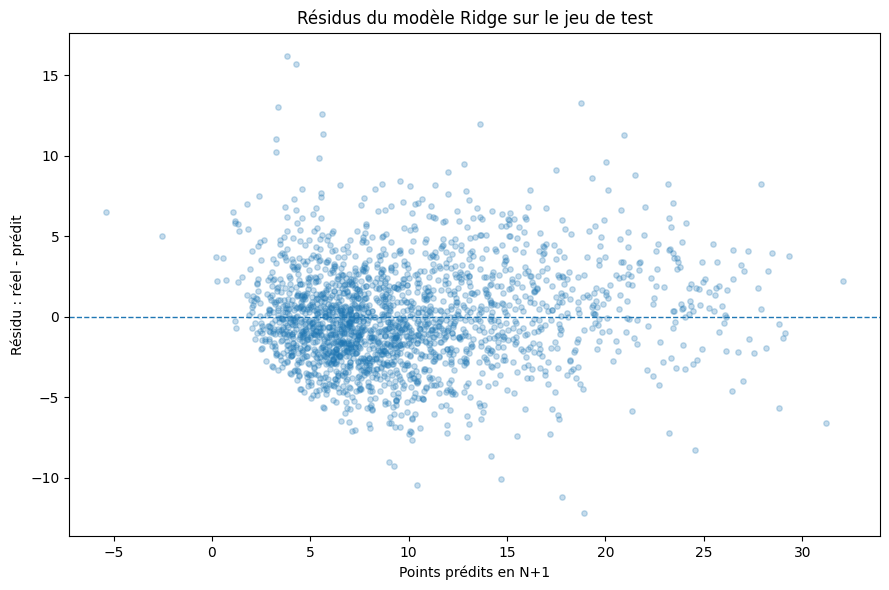

In [105]:
import matplotlib.pyplot as plt


plt.figure(
    figsize=(9, 6)
)


plt.scatter(
    test_results["y_pred"],
    test_results["residual"],
    alpha=0.25,
    s=15
)


plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)


plt.xlabel(
    "Points prédits en N+1"
)

plt.ylabel(
    "Résidu : réel - prédit"
)

plt.title(
    "Résidus du modèle Ridge sur le jeu de test"
)


plt.tight_layout()


plt.savefig(
    REPORT_DIR
    / "residuals_test.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

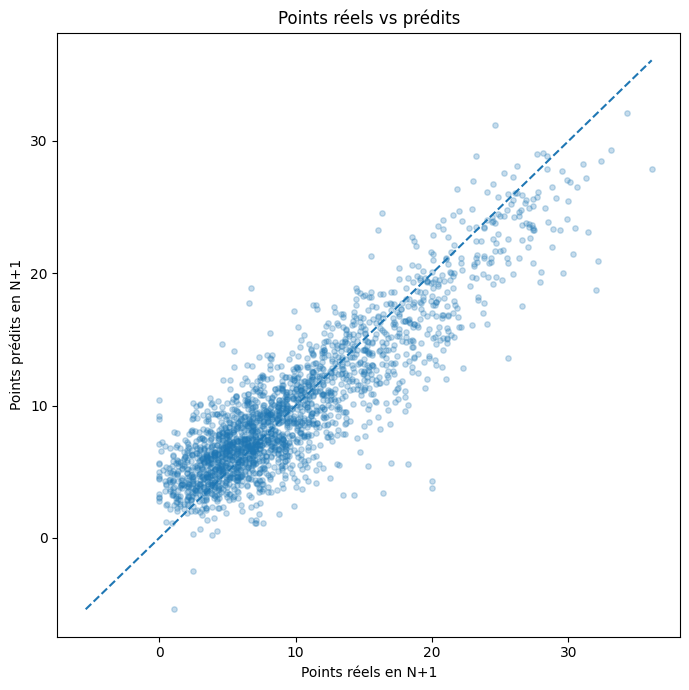

In [106]:
plt.figure(
    figsize=(7, 7)
)


plt.scatter(
    y_test,
    test_pred,
    alpha=0.25,
    s=15
)


min_value = min(
    y_test.min(),
    test_pred.min()
)

max_value = max(
    y_test.max(),
    test_pred.max()
)


plt.plot(
    [
        min_value,
        max_value,
    ],
    [
        min_value,
        max_value,
    ],
    linestyle="--"
)


plt.xlabel(
    "Points réels en N+1"
)

plt.ylabel(
    "Points prédits en N+1"
)

plt.title(
    "Points réels vs prédits"
)


plt.tight_layout()


plt.savefig(
    REPORT_DIR
    / "actual_vs_predicted_test.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

## 13. Interprétation du modèle

Le Ridge étant un modèle linéaire, son interprétation repose sur les
coefficients associés aux variables après preprocessing.

Un coefficient positif est associé à une augmentation de la prédiction,
tandis qu'un coefficient négatif est associé à une diminution.

In [107]:
feature_names = (
    final_model
    .named_steps["preprocessing"]
    .get_feature_names_out()
)


coefficients = (
    final_model
    .named_steps["modele"]
    .coef_
)


coefficient_table = pd.DataFrame({
    "feature":
        feature_names,

    "coefficient":
        coefficients,
})


coefficient_table[
    "abs_coefficient"
] = (
    coefficient_table[
        "coefficient"
    ]
    .abs()
)


coefficient_table = (
    coefficient_table
    .sort_values(
        "abs_coefficient",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


display(
    coefficient_table.head(20)
)

,feature,coefficient,abs_coefficient
0,numeric__FGM_PG,0.919016,0.919016
1,numeric__FGM,0.919016,0.919016
2,numeric__AGE,-0.911228,0.911228
3,numeric__PTS,0.819366,0.819366
4,numeric__FTM,0.545534,0.545534
5,numeric__MIN_PREV,-0.500969,0.500969
6,numeric__WNBA_FANTASY_PTS,0.470343,0.470343
7,numeric__FGA,0.457709,0.457709
8,numeric__FGA_PG,0.457709,0.457709
9,numeric__NBA_FANTASY_PTS,0.411427,0.411427


In [108]:
coefficient_table.to_csv(
    REPORT_DIR 
    / "ridge_coefficients.csv",
    index=False,
    encoding="utf-8"
)

## 14. Interprétation du modèle

Le modèle final étant une régression Ridge, son interprétation repose sur les
coefficients associés aux variables après preprocessing.

Comme les variables numériques sont standardisées, la valeur absolue des
coefficients permet de comparer leur influence relative sur la prédiction.

Un coefficient positif est associé à une augmentation de la prédiction de
`pts_next_season`, tandis qu'un coefficient négatif est associé à une diminution.

In [111]:
feature_names = (
    final_model
    .named_steps["preprocessing"]
    .get_feature_names_out()
)


coefficients = (
    final_model
    .named_steps["modele"]
    .coef_
)


coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients,
})


coefficient_table["abs_coefficient"] = (
    coefficient_table["coefficient"].abs()
)


coefficient_table = (
    coefficient_table
    .sort_values(
        "abs_coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    coefficient_table.head(20)
)

,feature,coefficient,abs_coefficient
0,numeric__FGM_PG,0.919016,0.919016
1,numeric__FGM,0.919016,0.919016
2,numeric__AGE,-0.911228,0.911228
3,numeric__PTS,0.819366,0.819366
4,numeric__FTM,0.545534,0.545534
5,numeric__MIN_PREV,-0.500969,0.500969
6,numeric__WNBA_FANTASY_PTS,0.470343,0.470343
7,numeric__FGA,0.457709,0.457709
8,numeric__FGA_PG,0.457709,0.457709
9,numeric__NBA_FANTASY_PTS,0.411427,0.411427


In [112]:
coefficient_table.to_csv(
    REPORT_DIR / "ridge_coefficients.csv",
    index=False,
    encoding="utf-8"
)

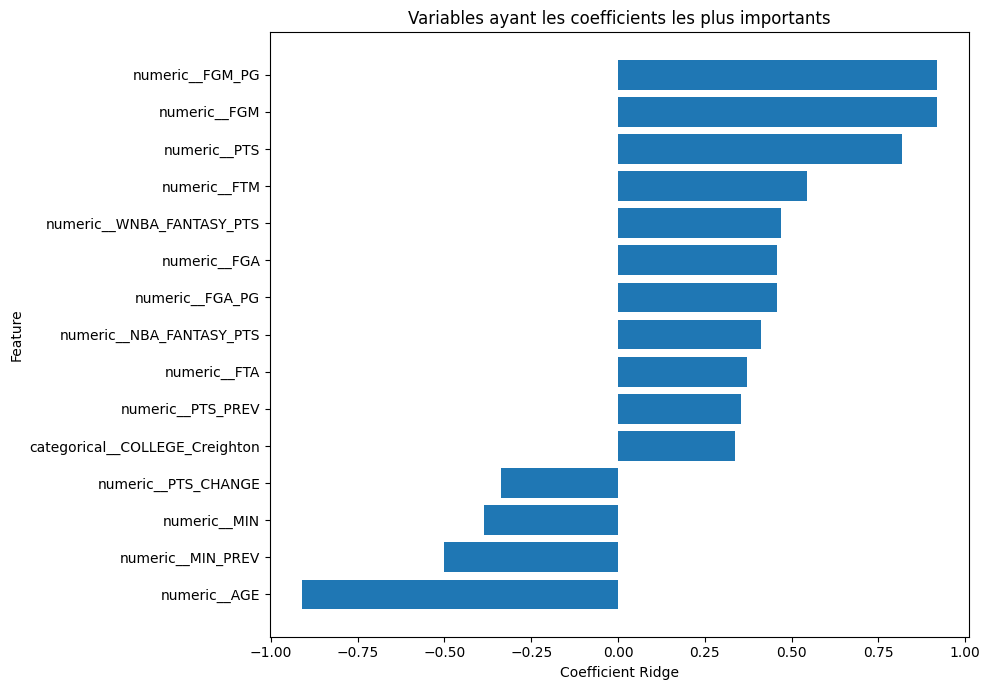

In [113]:
import matplotlib.pyplot as plt


top_coefficients = (
    coefficient_table
    .head(15)
    .sort_values("coefficient")
)


plt.figure(
    figsize=(10, 7)
)


plt.barh(
    top_coefficients["feature"],
    top_coefficients["coefficient"]
)


plt.xlabel(
    "Coefficient Ridge"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Variables ayant les coefficients les plus importants"
)


plt.tight_layout()


plt.savefig(
    REPORT_DIR / "ridge_top_coefficients.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

## 15. Livraison du modèle final

La pipeline complète est sauvegardée afin de conserver dans un seul objet :

- l'imputation ;
- la standardisation ;
- l'encodage des variables catégorielles ;
- le modèle Ridge final.

Cela permet d'effectuer directement des prédictions à partir de nouvelles
données brutes ayant la même structure que les features d'entraînement.

In [121]:
from pathlib import Path
from datetime import date
import joblib


MODEL_DIR = (
    PROJECT_ROOT
    / "models"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


DATE_TAG = date.today().strftime("%Y%m%d")


MODEL_PATH = (
    MODEL_DIR
    / f"nba_pts_ridge_pipeline_v1_{DATE_TAG}.joblib"
)


joblib.dump(
    final_model,
    MODEL_PATH
)


print(
    "Modèle sauvegardé :",
    MODEL_PATH
)

Modèle sauvegardé : c:\Users\USER\OneDrive\LiveCampus\master\cours\machine learning\final\Model\models\nba_pts_ridge_pipeline_v1_20261005.joblib


In [117]:
SRC_DIR = (
    PROJECT_ROOT
    / "src"
)

SRC_DIR.mkdir(
    parents=True,
    exist_ok=True
)


(
    SRC_DIR
    / "__init__.py"
).touch()


preprocessing_code = """import numpy as np
import pandas as pd


def normalize_categorical_missing(X):
    X = X.copy()

    if isinstance(X, pd.DataFrame):
        X = X.astype(object)
        X = X.where(
            pd.notna(X),
            np.nan
        )

    else:
        X = np.asarray(
            X,
            dtype=object
        )

        X[
            pd.isna(X)
        ] = np.nan

    return X
"""


(
    SRC_DIR
    / "preprocessing.py"
).write_text(
    preprocessing_code,
    encoding="utf-8"
)


print(
    "Module créé :",
    SRC_DIR / "preprocessing.py"
)

Module créé : c:\Users\USER\OneDrive\LiveCampus\master\cours\machine learning\final\Model\src\preprocessing.py


In [115]:
loaded_model = joblib.load(
    MODEL_PATH
)


print(
    "Modèle rechargé :",
    loaded_model.named_steps["modele"]
)

Modèle rechargé : Ridge(alpha=100.0)


In [116]:
demo_X = X_test.iloc[:3].copy()


demo_pred = loaded_model.predict(
    demo_X
)


demo_results = pd.DataFrame({
    "PTS_N":
        demo_X["PTS"],

    "PTS_reel_N1":
        y_test.loc[
            demo_X.index
        ],

    "PTS_predit_N1":
        demo_pred,
})


display(
    demo_results
)

,PTS_N,PTS_reel_N1,PTS_predit_N1
2528,5.4,7.4,3.692791
2529,7.4,5.0,3.498386
2576,12.0,7.3,9.040092


## 17. Synthèse du modèle final

Le modèle retenu est une régression **Ridge avec alpha = 100**.

Il a été sélectionné après comparaison avec un Decision Tree et un Random Forest
au moyen d'une validation croisée temporelle à cinq folds.

Sur le jeu de test final, correspondant aux saisons 2017-18 à 2021-22, il obtient :

- **MAE : 2,393 PTS**
- **RMSE : 3,104 PTS**
- **R² : 0,775**

La baseline de persistance obtient une MAE de **2,558 PTS**.

Le Ridge réduit donc l'erreur absolue moyenne d'environ **6,5 %** par rapport
à cette baseline.

Le gain est modéré mais réel, d'autant plus que la persistance constitue déjà
une référence difficile à battre dans un problème où le scoring est fortement
corrélé d'une saison à la suivante.

## 18. Questions de réflexion

### Le gain est-il réel ?

Oui. Le Ridge réduit la MAE d'environ 6,5 % par rapport à la baseline de
persistance. Le gain reste modéré car cette baseline est déjà très performante.

### Pourquoi conserver un modèle simple ?

Le Random Forest obtenait une MAE presque identique sur la validation mais
présentait un écart beaucoup plus important entre entraînement et validation.

Le Ridge a donc été privilégié pour sa simplicité, sa stabilité et sa meilleure
capacité de généralisation.

### Peut-on faire totalement confiance au modèle ?

Non. Une erreur moyenne d'environ 2,4 points par match reste significative,
notamment pour les joueurs dont le rôle change fortement entre deux saisons.

Le modèle doit être considéré comme une aide à l'estimation et non comme une
prévision certaine.

### Quelle fuite aurait pu être dangereuse ?

L'utilisation d'informations de la saison N+1 ou d'un découpage aléatoire des
saisons aurait pu produire une estimation artificiellement optimiste des
performances.

Le split chronologique permet de mieux reproduire une situation réelle où le
passé est utilisé pour prédire le futur.

### Comment améliorer les performances ?

Une amélioration supplémentaire pourrait davantage provenir de nouvelles données
que d'un modèle plus complexe.

Des informations sur les blessures, changements de rôle, transferts, contrats
ou rotations d'équipe pourraient expliquer certaines fortes variations que les
statistiques de saison N ne permettent pas d'anticiper.

### Interprétation des coefficients

Les coefficients du Ridge confirment plusieurs résultats observés pendant
l'EDA.

Les variables liées à la production offensive actuelle occupent une place
importante dans le modèle, notamment :

- `FGM_PG` et `FGM`, liés aux tirs réussis ;
- `PTS`, correspondant au niveau de scoring actuel ;
- `FTM`, lié aux lancers francs marqués ;
- `FGA` et `FGA_PG`, représentant le volume de tirs.

Ces résultats sont cohérents avec la Phase 5, où le volume offensif et
notamment `FGA` étaient fortement associés aux points de la saison suivante.

`AGE` possède un coefficient fortement négatif. Cela correspond également
aux résultats de l'EDA : la progression offensive diminue avec l'âge et les
joueurs plus âgés ont davantage tendance à régresser.

Certains coefficients sont moins intuitifs. Par exemple, `MIN` et `MIN_PREV`
apparaissent négatifs alors que le temps de jeu était positivement associé
au niveau de points futur dans l'EDA. Cela ne constitue pas une contradiction :
le Ridge estime l'effet d'une variable en tenant compte simultanément des
nombreuses autres variables corrélées. L'effet du temps de jeu peut donc être
partiellement capté par `PTS`, `FGA`, `FGM` ou l'usage offensif.

La présence de `COLLEGE_Creighton` parmi les coefficients importants est plus
surprenante. Cette variable catégorielle peut correspondre à un effet spécifique
à un petit nombre de joueurs et ne doit pas être interprétée comme une relation
causale ou généralisable.

Globalement, les coefficients confirment que la production offensive actuelle,
le volume de tirs et la phase de carrière sont parmi les principaux signaux
utilisés par le modèle.

### Limites de l'interprétation

Les coefficients Ridge ne doivent pas être interprétés comme des effets causaux.

De nombreuses statistiques NBA sont fortement corrélées entre elles. Le Ridge
répartit donc l'information entre plusieurs variables et réduit leurs
coefficients grâce à la régularisation.

Les coefficients des variables numériques standardisées sont relativement
comparables entre eux, mais leur comparaison avec les variables catégorielles
encodées en one-hot doit rester prudente.